In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("Zomato_Dataset.csv")

print(df.head())

   RestaurantID          RestaurantName  CountryCode              City  \
0       6317637        Le Petit Souffle          162       Makati City   
1       6304287        Izakaya Kikufuji          162       Makati City   
2       6300002  Heat - Edsa Shangri-La          162  Mandaluyong City   
3       6318506                    Ooma          162  Mandaluyong City   
4       6314302             Sambo Kojin          162  Mandaluyong City   

                                             Address  \
0  Third Floor| Century City Mall| Kalayaan Avenu...   
1  Little Tokyo| 2277 Chino Roces Avenue| Legaspi...   
2  Edsa Shangri-La| 1 Garden Way| Ortigas| Mandal...   
3  Third Floor| Mega Fashion Hall| SM Megamall| O...   
4  Third Floor| Mega Atrium| SM Megamall| Ortigas...   

                                     Locality  \
0   Century City Mall| Poblacion| Makati City   
1  Little Tokyo| Legaspi Village| Makati City   
2  Edsa Shangri-La| Ortigas| Mandaluyong City   
3      SM Megamall| Or

In [3]:
print(df.shape)

print(df.columns)

print(df.info())

(9551, 17)
Index(['RestaurantID', 'RestaurantName', 'CountryCode', 'City', 'Address',
       'Locality', 'LocalityVerbose', 'Cuisines', 'Currency',
       'Has_Table_booking', 'Has_Online_delivery', 'Is_delivering_now',
       'Switch_to_order_menu', 'Price_range', 'Votes', 'Average_Cost_for_two',
       'Rating'],
      dtype='str')
<class 'pandas.DataFrame'>
RangeIndex: 9551 entries, 0 to 9550
Data columns (total 17 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   RestaurantID          9551 non-null   int64  
 1   RestaurantName        9551 non-null   str    
 2   CountryCode           9551 non-null   int64  
 3   City                  9551 non-null   str    
 4   Address               9551 non-null   str    
 5   Locality              9551 non-null   str    
 6   LocalityVerbose       9551 non-null   str    
 7   Cuisines              9542 non-null   str    
 8   Currency              9551 non-null   str    
 9   Ha

In [4]:
restaurant_counts = df["RestaurantName"].value_counts()

print(restaurant_counts.head(10))

RestaurantName
Cafe Coffee Day     83
Domino's Pizza      79
Subway              63
Green Chick Chop    51
McDonald's          48
Keventers           34
Pizza Hut           30
Giani               29
Baskin Robbins      28
Barbeque Nation     26
Name: count, dtype: int64


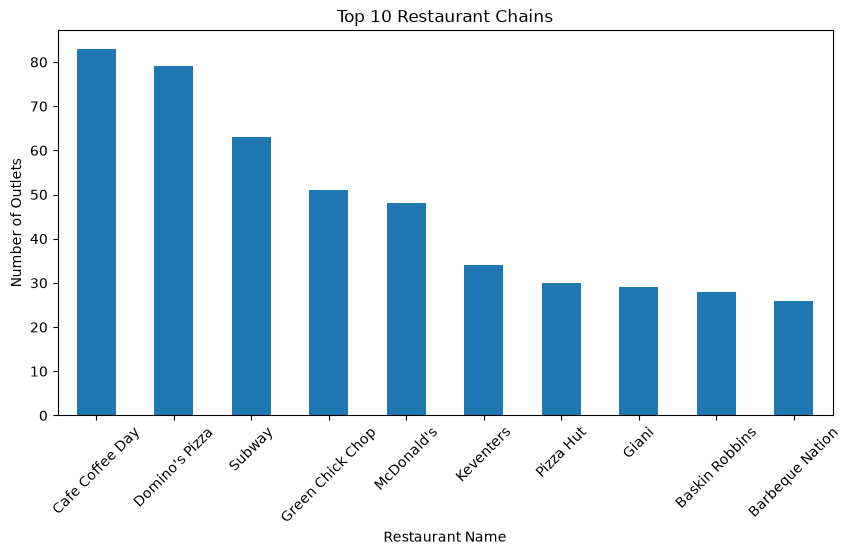

In [5]:
restaurant_counts.head(10).plot(kind="bar", figsize=(10,5))

plt.title("Top 10 Restaurant Chains")
plt.xlabel("Restaurant Name")
plt.ylabel("Number of Outlets")
plt.xticks(rotation=45)
plt.show()

In [7]:
chain_ratings = df.groupby("RestaurantName")["Rating"].mean()

chain_ratings = chain_ratings.sort_values(ascending=False)

print(chain_ratings.head(10))

RestaurantName
Zolocrust - Hotel Clarks Amer               4.9
Oakwood Cafe                                4.9
Duck & Waffle                               4.9
Yellow Dog Eats                             4.9
The Great Indian Pub                        4.9
Shorts Burger and Shine                     4.9
Flat Iron                                   4.9
Pom Pom's Teahouse and Sandwicheria         4.9
Spiral - Sofitel Philippine Plaza Manila    4.9
Sheroes Hangout                             4.9
Name: Rating, dtype: float64


In [8]:
restaurant_counts = df["RestaurantName"].value_counts()

restaurant_chains = restaurant_counts[restaurant_counts > 1]

print("Total Restaurant Chains:", len(restaurant_chains))

print(restaurant_chains.head(10))

Total Restaurant Chains: 734
RestaurantName
Cafe Coffee Day     83
Domino's Pizza      79
Subway              63
Green Chick Chop    51
McDonald's          48
Keventers           34
Pizza Hut           30
Giani               29
Baskin Robbins      28
Barbeque Nation     26
Name: count, dtype: int64


In [9]:
df["Rating_num"] = pd.to_numeric(df["Rating"], errors="coerce")
df["Votes_num"] = pd.to_numeric(df["Votes"], errors="coerce")

chain_summary = df.groupby("RestaurantName").agg(
    Outlet_Count=("RestaurantName", "size"),
    Average_Rating=("Rating_num", "mean"),
    Total_Votes=("Votes_num", "sum")
)

chain_summary = chain_summary[chain_summary["Outlet_Count"] > 1]

print(chain_summary.head(10))

                           Outlet_Count  Average_Rating  Total_Votes
RestaurantName                                                      
10 Downing Street                     2        4.000000          670
221 B Baker Street                    3        3.366667          215
34 Parkstreet Lane                    2        3.050000           31
34, Chowringhee Lane                 12        2.875000          777
4700BC Popcorn                        2        3.500000          176
6 Pack Momos                          2        1.900000            8
A Piece of Paris                      2        3.750000           81
AB's - Absolute Barbecues             4        4.825000        13400
AB's Absolute Barbecues               2        4.850000         3151
Aap Ki Khatir                         2        1.000000            0


In [10]:
top_chains = chain_summary.sort_values(
    by="Outlet_Count", ascending=False
).head(10)

print(top_chains)

                  Outlet_Count  Average_Rating  Total_Votes
RestaurantName                                             
Cafe Coffee Day             83        2.612048         2428
Domino's Pizza              79        2.803797         6643
Subway                      63        2.939683         6124
Green Chick Chop            51        2.809804          964
McDonald's                  48        3.360417         5291
Keventers                   34        3.017647         1263
Pizza Hut                   30        3.353333         4961
Giani                       29        2.862069          854
Baskin Robbins              28        2.289286          428
Barbeque Nation             26        4.353846        28142


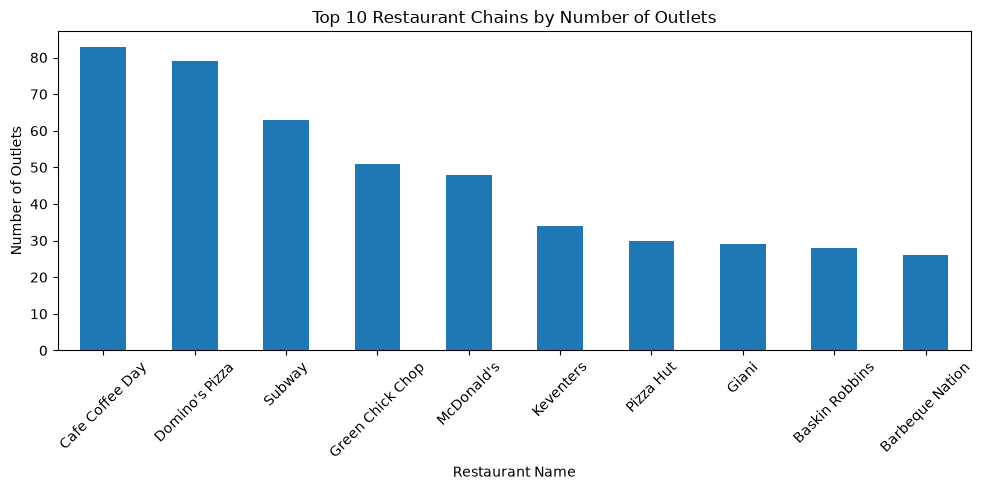

In [11]:
top_chains["Outlet_Count"].plot(
    kind="bar", figsize=(10, 5)
)

plt.title("Top 10 Restaurant Chains by Number of Outlets")
plt.xlabel("Restaurant Name")
plt.ylabel("Number of Outlets")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [12]:
top_rated_chains = chain_summary.sort_values(
    by="Average_Rating", ascending=False
).head(10)

print(top_rated_chains[["Average_Rating", "Outlet_Count"]])

                           Average_Rating  Outlet_Count
RestaurantName                                         
Talaga Sampireun                    4.900             3
AB's Absolute Barbecues             4.850             2
Silantro Fil-Mex                    4.850             2
AB's - Absolute Barbecues           4.825             4
Naturals Ice Cream                  4.800             2
Gymkhana                            4.700             2
The Cheesecake Factory              4.650             2
Dishoom                             4.600             2
Garota de Ipanema                   4.600             2
Chili's                             4.580             5


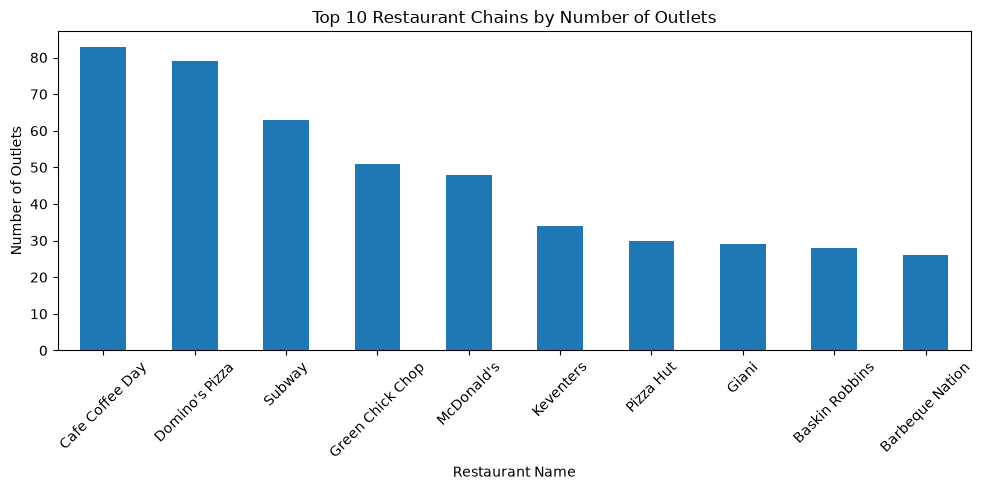

In [13]:
top_chains["Outlet_Count"].plot(
    kind="bar", figsize=(10, 5)
)

plt.title("Top 10 Restaurant Chains by Number of Outlets")
plt.xlabel("Restaurant Name")
plt.ylabel("Number of Outlets")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [14]:
top_rated_chains = chain_summary.sort_values(
    by="Average_Rating", ascending=False
).head(10)

print(top_rated_chains[["Average_Rating", "Outlet_Count"]])

                           Average_Rating  Outlet_Count
RestaurantName                                         
Talaga Sampireun                    4.900             3
AB's Absolute Barbecues             4.850             2
Silantro Fil-Mex                    4.850             2
AB's - Absolute Barbecues           4.825             4
Naturals Ice Cream                  4.800             2
Gymkhana                            4.700             2
The Cheesecake Factory              4.650             2
Dishoom                             4.600             2
Garota de Ipanema                   4.600             2
Chili's                             4.580             5


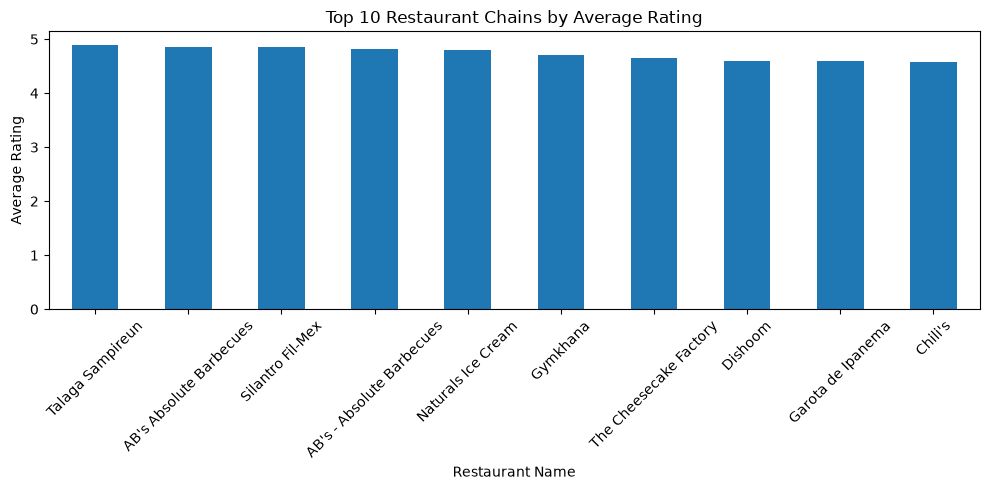

In [15]:
top_rated_chains["Average_Rating"].plot(
    kind="bar", figsize=(10, 5)
)

plt.title("Top 10 Restaurant Chains by Average Rating")
plt.xlabel("Restaurant Name")
plt.ylabel("Average Rating")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [16]:
popular_chains = chain_summary.sort_values(
    by="Total_Votes", ascending=False
).head(10)

print(popular_chains[["Total_Votes", "Outlet_Count", "Average_Rating"]])

                           Total_Votes  Outlet_Count  Average_Rating
RestaurantName                                                      
Barbeque Nation                  28142            26        4.353846
AB's - Absolute Barbecues        13400             4        4.825000
Big Chill                        10853             4        4.475000
Farzi Cafe                       10098             6        4.366667
Truffles                          9682             2        3.950000
Chili's                           8156             5        4.580000
Joey's Pizza                      7807             2        4.250000
Big Yellow Door                   7511             3        4.266667
Saravana Bhavan                   7238             3        4.133333
Starbucks                         7139            18        3.805556


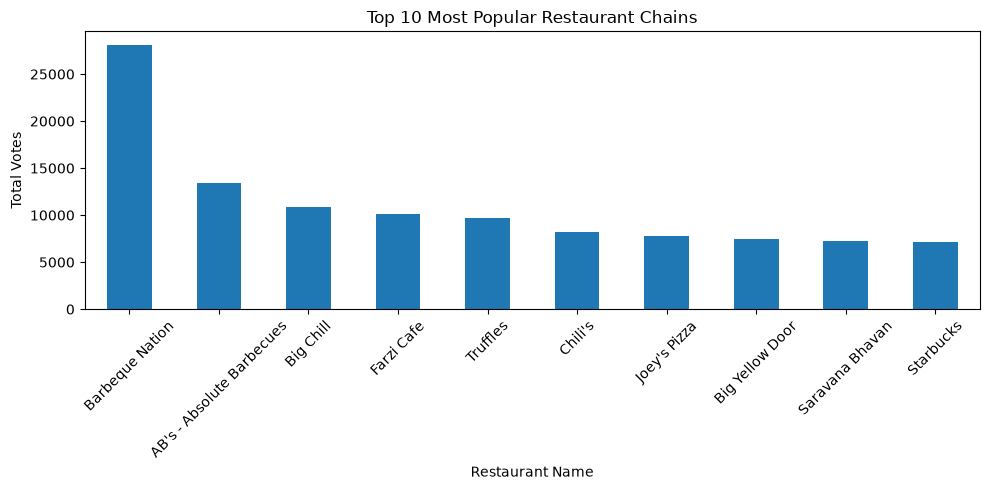

In [17]:
popular_chains["Total_Votes"].plot(
    kind="bar", figsize=(10, 5)
)

plt.title("Top 10 Most Popular Restaurant Chains")
plt.xlabel("Restaurant Name")
plt.ylabel("Total Votes")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [18]:
chain_summary.to_csv("Restaurant_Chain_Analysis.csv")

print("Restaurant Chain Analysis saved successfully!")

Restaurant Chain Analysis saved successfully!


In [19]:
print("RESTAURANT CHAINS ANALYSIS")

print("\nTop Chain by Number of Outlets:")
print(chain_summary["Outlet_Count"].idxmax())

print("\nHighest Average Rated Chain:")
print(chain_summary["Average_Rating"].idxmax())

print("\nMost Popular Chain by Votes:")
print(chain_summary["Total_Votes"].idxmax())

RESTAURANT CHAINS ANALYSIS

Top Chain by Number of Outlets:
Cafe Coffee Day

Highest Average Rated Chain:
Talaga Sampireun

Most Popular Chain by Votes:
Barbeque Nation


### Conclusion

The Restaurant Chains Analysis helped identify restaurants with multiple outlets in the Zomato dataset.

The analysis compared restaurant chains based on:

1. Number of outlets.
2. Average customer ratings.
3. Total customer votes.

Bar graphs were used to visualize the top restaurant chains and compare their performance.

This analysis helped understand restaurant popularity, customer preferences and ratings using Python and Pandas.